# 02 · Transferencia LP-VT entre datasets

**Pregunta.** ¿Qué descriptores separan LP de VT en todos los sistemas, y cuánto se pierde al entrenar en un sistema (fuente) y clasificar en otro (destino)?

1. AUC por sistema de cada descriptor (`transferibilidad_auc.csv`, `transferibilidad_ranking.csv`).
2. Matrices fuente→destino de Gm y resumen por escalón (`transferencia_resumen_*.csv`).
3. Una demostración ejecutable con los datos de validación.

Los resultados incluyen sistemas de OVDAS (solo valores agregados); la demostración usa solo `../datos/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
pd.set_option("display.width", 160, "display.max_columns", 30)
DATOS, RES = Path("../datos"), Path("../resultados")

## 1. AUC LP-VT por sistema y descriptor (ventana fija)

In [2]:
auc = pd.read_csv(RES / "transferibilidad_auc.csv")
rk = pd.read_csv(RES / "transferibilidad_ranking.csv")
rk_f = rk[rk.ventana == "fija"].sort_values("puntaje", ascending=False)
rk_f[["descriptor", "sentido", "auc_mediana", "iqr", "auc_min", "sistema_min", "invertidos"]].round(3)

,descriptor,sentido,auc_mediana,iqr,auc_min,sistema_min,invertidos
0,FI,LP<VT,0.929,0.066,0.730,Alaska,0
1,DET,LP>VT,0.874,0.089,0.554,Ruiz-Olleta,0
2,SR,LP<VT,0.868,0.086,0.652,Ruiz-Olleta,0
3,Lentr,LP>VT,0.741,0.094,0.403,Norte de California,1
4,Wmax,LP<VT,0.724,0.083,0.406,Villarrica,1
5,Wdiv,LP>VT,0.724,0.083,0.406,Villarrica,1
6,LAM,LP>VT,0.764,0.139,0.454,Norte de California,2
7,L,LP>VT,0.725,0.104,0.390,Norte de California,1
8,fpeak,LP<VT,0.790,0.183,0.590,Hudson,0
9,W,LP>VT,0.701,0.132,0.583,Copahue,0


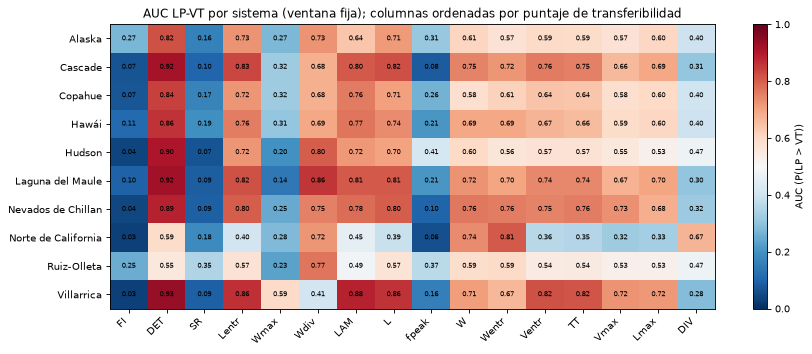

In [3]:
a = auc[auc.ventana == "fija"].pivot(index="sistema", columns="descriptor", values="auc")
a = a[rk_f.descriptor]
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(a.values, cmap="RdBu_r", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(a.shape[1])); ax.set_xticklabels(a.columns, rotation=45, ha="right")
ax.set_yticks(range(a.shape[0])); ax.set_yticklabels(a.index)
for i in range(a.shape[0]):
    for j in range(a.shape[1]):
        ax.text(j, i, f"{a.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, label="AUC (P(LP > VT))")
ax.set_title("AUC LP-VT por sistema (ventana fija); columnas ordenadas por puntaje de transferibilidad")
fig.tight_layout()

## 2. Matrices fuente→destino (M2, LP-VT, ventana fija)

Gm = media geométrica de los recall de LP y VT, promedio sobre sorteos de entrenamiento de 100 eventos por clase de la fuente. Escalado `fuente`.

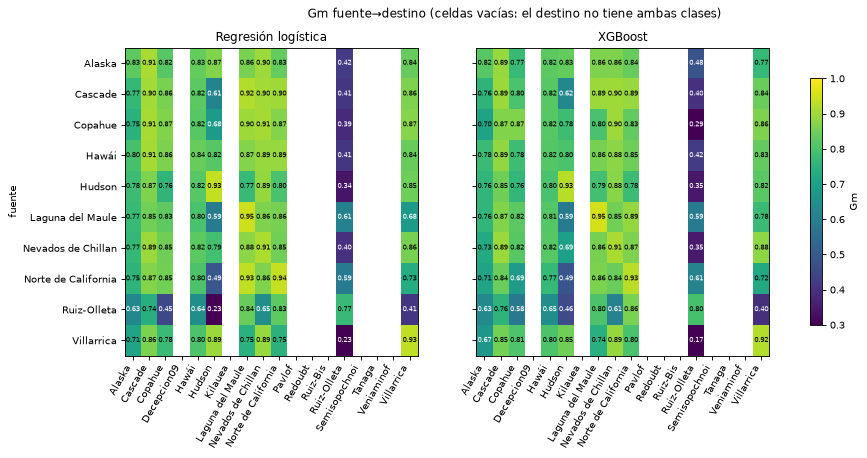

In [4]:
pares = pd.read_csv(RES / "transferencia_resumen_pares.csv")
m2 = pares[(pares.matriz == "M2") & (pares.ventana == "fija") & (pares.escalado == "fuente")]
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, mod in zip(ejes, ["log", "xgb"]):
    p = m2[m2.modelo == mod].pivot(index="fuente", columns="destino", values="gm")
    im = ax.imshow(p.values, cmap="viridis", vmin=0.3, vmax=1, aspect="auto")
    ax.set_xticks(range(p.shape[1])); ax.set_xticklabels(p.columns, rotation=60, ha="right")
    ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            v = p.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                        color="w" if v < .7 else "k")
    ax.set_title({"log": "Regresión logística", "xgb": "XGBoost"}[mod])
ejes[0].set_ylabel("fuente"); fig.colorbar(im, ax=ejes, label="Gm", shrink=.8)
fig.suptitle("Gm fuente→destino (celdas vacías: el destino no tiene ambas clases)");

Resumen por escalón (diagonal, misma agencia, entre agencias), M2:

In [5]:
esc = pd.read_csv(RES / "transferencia_resumen_escalones.csv")
esc[esc.matriz == "M2"].round(3)

,matriz,ventana,escalado,modelo,escalon,n_pares,gm_por_par,gm_por_fuente,gm_por_destino,perdida_por_par
24,M2,coda,fuente,log,0 diagonal,10,0.908,0.908,0.908,0.000
25,M2,coda,fuente,log,2 misma agencia,20,0.804,0.781,0.782,-0.122
26,M2,coda,fuente,log,3 entre agencias,70,0.806,0.776,0.830,-0.083
27,M2,coda,fuente,xgb,0 diagonal,10,0.908,0.908,0.908,0.000
28,M2,coda,fuente,xgb,2 misma agencia,20,0.818,0.830,0.812,-0.068
29,M2,coda,fuente,xgb,3 entre agencias,70,0.789,0.786,0.823,-0.085
30,M2,coda,sistema,log,0 diagonal,10,0.908,0.908,0.908,0.000
31,M2,coda,sistema,log,2 misma agencia,20,0.640,0.656,0.669,-0.272
32,M2,coda,sistema,log,3 entre agencias,70,0.757,0.769,0.792,-0.117
33,M2,coda,sistema,xgb,0 diagonal,10,0.908,0.908,0.908,0.000


Destinos con una sola clase (se reporta el recall de esa clase):

In [6]:
pd.read_csv(RES / "transferencia_resumen_una_clase.csv", header=[0, 1], index_col=0).round(3)

ventana         coda          fija       
modelo           log    xgb    log    xgb
destino                                  
Decepcion09    0.993  0.994  0.994  0.992
Kilauea        0.760  0.732  0.744  0.746
Pavlof         0.990  0.996  0.918  0.938
Redoubt        0.762  0.780  0.660  0.650
Ruiz-Bis       0.060  0.047  0.029  0.050
Semisopochnoi  0.975  0.974  0.968  0.961
Tanaga         0.958  0.960  0.880  0.868
Veniaminof     0.996  0.996  0.991  0.983

## 3. Demostración: entrenar en Cascade, clasificar en otros sistemas

Regresión logística (L2, estandarización con la media y la desviación de la fuente) entrenada con 100 LP y 100 VT de Cascade, evaluada en los eventos restantes de Cascade y en todos los LP y VT de Hawái, Norte de California y Alaska. Diez sorteos. Es una versión reducida del diseño de `transferencia.py` (sin ajuste de C ni XGBoost).

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score

F16 = ["DET", "L", "Lmax", "DIV", "Lentr", "LAM", "TT", "Vmax", "Ventr", "W",
       "Wmax", "Wdiv", "Wentr", "fpeak", "SR", "FI"]
d = pd.read_parquet(DATOS / "features16_fija.parquet")
d = d[(d.motivo == "") & ~d.duplicado.fillna(False).astype(bool) & d.clase.isin(["LP", "VT"])]

def gm(y, p):
    r = recall_score(y, p, labels=["LP", "VT"], average=None)
    return np.sqrt(r[0] * r[1]), r[0], r[1]

FUENTE, DESTINOS = "Cascade", ["Hawái", "Norte de California", "Alaska"]
src = d[d.sistema == FUENTE]
filas = []
for rep in range(10):
    tr = src.groupby("clase").sample(100, random_state=rep)
    resto = src.drop(tr.index)
    x = tr[F16].fillna(tr[F16].median())
    m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)).fit(x, tr.clase)
    for nombre, g in [(FUENTE + " (resto)", resto)] + [(s, d[d.sistema == s]) for s in DESTINOS]:
        xg = g[F16].fillna(tr[F16].median())
        filas.append((rep, nombre, *gm(g.clase, m.predict(xg))))
r = pd.DataFrame(filas, columns=["rep", "destino", "gm", "rec_LP", "rec_VT"])
r.groupby("destino")[["gm", "rec_LP", "rec_VT"]].agg(["mean", "std"]).round(3)

gm        rec_LP        rec_VT       
                      mean    std   mean    std   mean    std
destino                                                      
Alaska               0.800  0.018  0.800  0.032  0.800  0.020
Cascade (resto)      0.908  0.019  0.904  0.020  0.912  0.033
Hawái                0.826  0.013  0.835  0.012  0.818  0.032
Norte de California  0.903  0.025  0.857  0.014  0.952  0.052

La pérdida respecto de la diagonal (Cascade resto) mide cuánto cuesta cambiar de sistema sin etiquetas del destino; ese es el punto de partida de la curva de presupuesto (notebook 03).